# Regression

In [1]:
# Importing the modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Fetching the dataset

In [2]:
housing_dataset=fetch_california_housing(as_frame=True)

## Converting the data to dataframe

In [3]:
data=housing_dataset.frame

## Viewing the first 10 rows of the dataset

In [4]:
data.head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


## Displaying information about the dataset

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## Statistical analysis of the dataset

In [6]:
data.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## Creating a copy of the dataset

In [7]:
data_copy=data.copy()

## Checking for duplicate rows

In [8]:
data_copy.duplicated().sum()

np.int64(0)

***No duplicate rows have been identified in the dataset.***

## Checking for missing values

In [9]:
data_copy.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

***No missing values have been identified in the dataset.***

## Analyzing the columns

### **MedInc column**

#### Checking for outliers

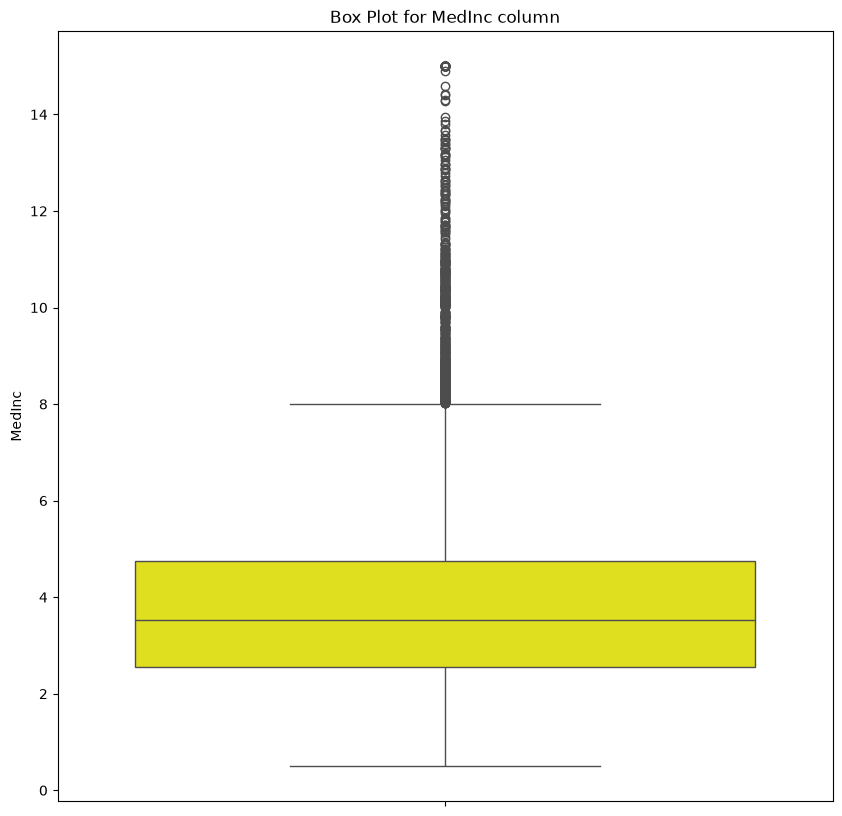

In [10]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='MedInc', color='yellow')
ax.set_title("Box Plot for MedInc column")
plt.show()

***Outliers have been identified in the MedInc column.***

#### Checking for skewness

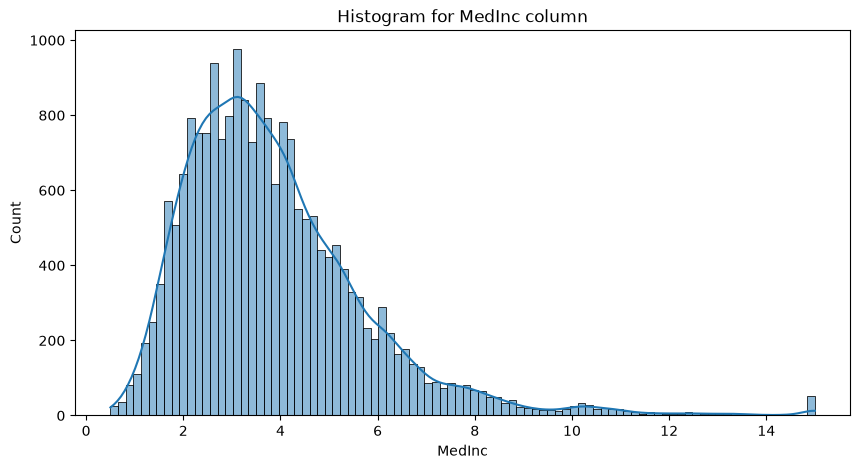

In [11]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='MedInc', kde=True)
ax.set_title("Histogram for MedInc column")
plt.show()

In [12]:
print(f"Skewness: {data_copy['MedInc'].skew()}")

Skewness: 1.6466567021344465


***The MedInc column is positively skewed. So log transformation has to be performed on this column.***

In [13]:
# Adding columns to column list that require log transformation
log_columns=['MedInc']

### **HouseAge column**

#### Checking for outliers

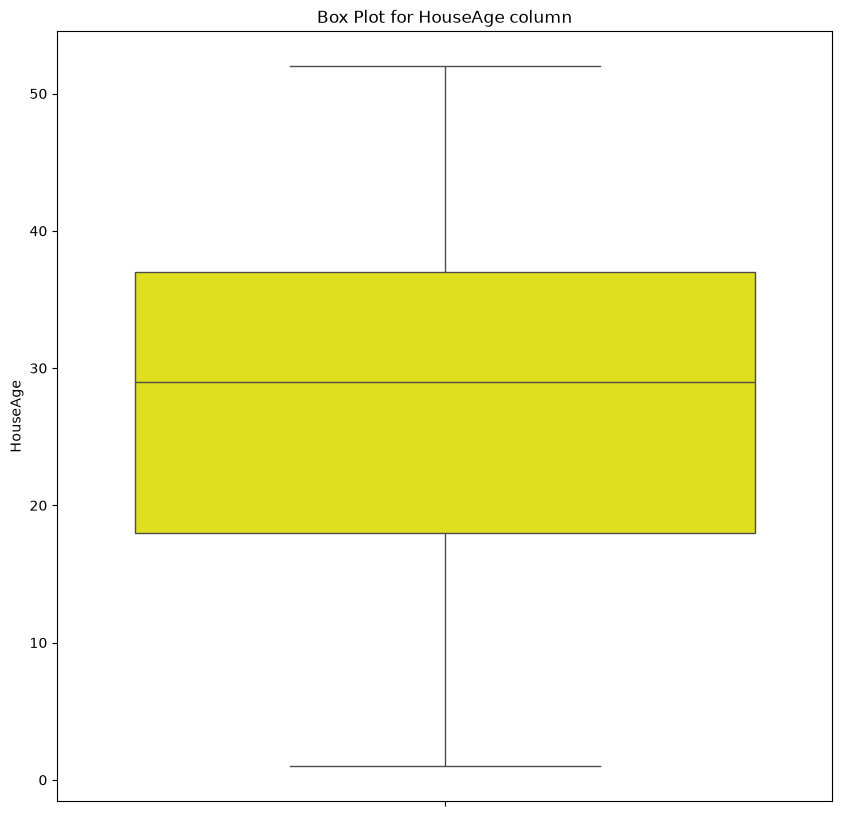

In [14]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='HouseAge', color='yellow')
ax.set_title("Box Plot for HouseAge column")
plt.show()

***No outliers have been identified in the HouseAge column.***

#### Checking for skewness

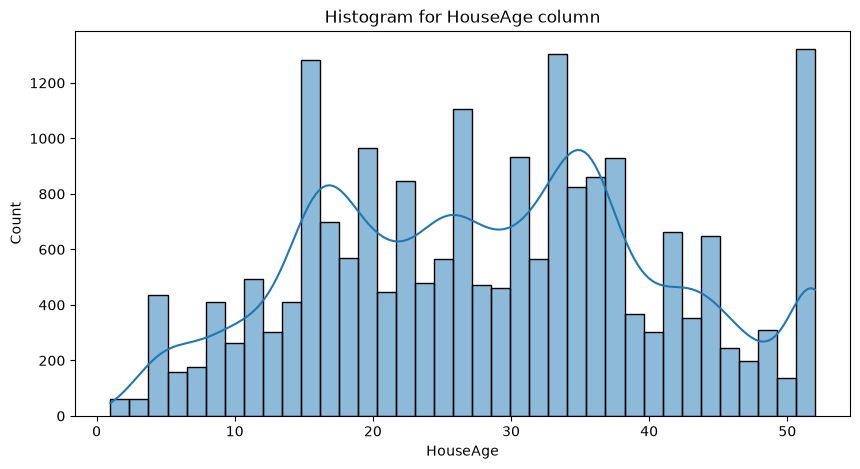

In [15]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='HouseAge', kde=True)
ax.set_title("Histogram for HouseAge column")
plt.show()

In [16]:
print(f"Skewness: {data_copy['HouseAge'].skew()}")

Skewness: 0.06033063759913685


***The HouseAge column is almost symmetrical.***

### **AveRooms column**

#### Checking for outliers

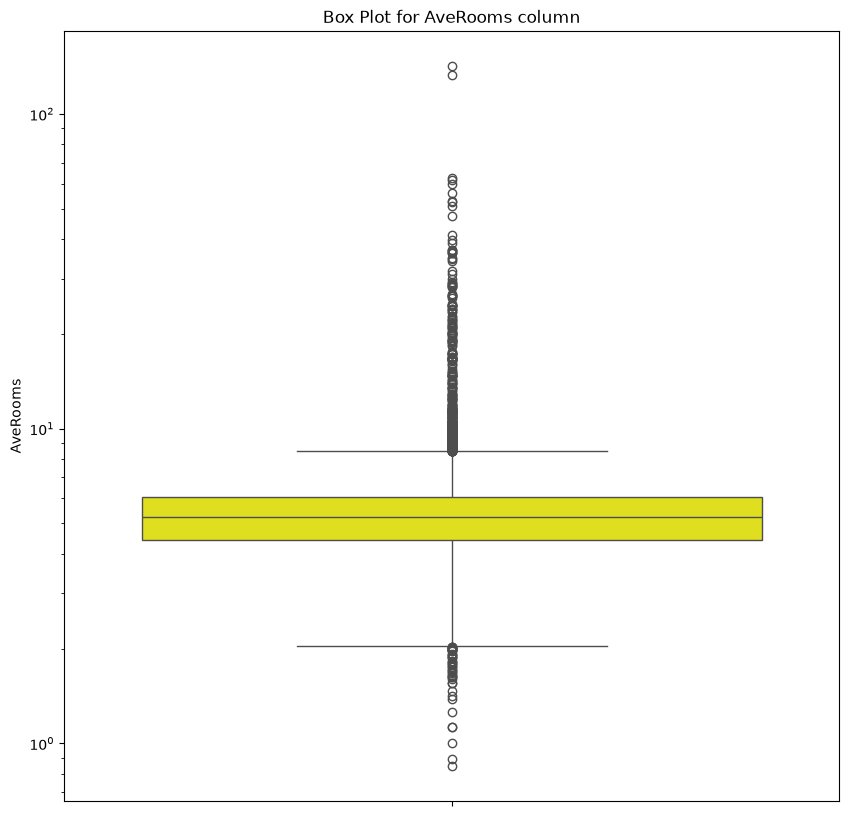

In [17]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='AveRooms', color='yellow')
ax.set_title("Box Plot for AveRooms column")
ax.set_yscale('log')
plt.show()

***A logarithmic scale is used to make the box plot visible.***

***Outliers have been identified in the AveRooms column.***

#### Checking for Skewness

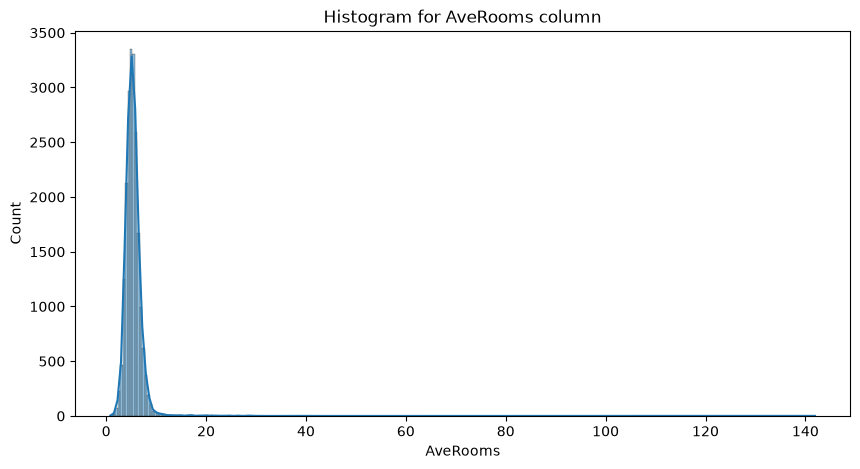

In [18]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='AveRooms', kde=True)
ax.set_title("Histogram for AveRooms column")
plt.show()

In [19]:
print(f"Skewness: {data_copy['AveRooms'].skew()}")

Skewness: 20.69786895671065


***The AveRooms column is positively skewed. So log transformation has to be performed on this column.***

In [20]:
log_columns.append('AveRooms')

### **AveBedrms column**

#### Checking for outliers

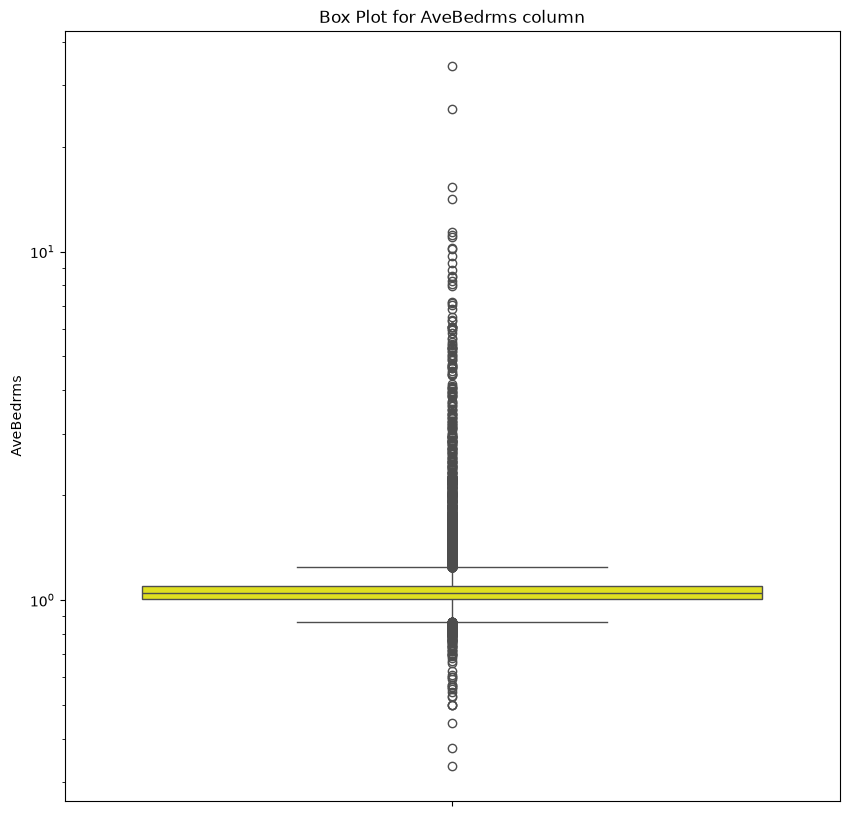

In [21]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='AveBedrms', color='yellow')
ax.set_title("Box Plot for AveBedrms column")
ax.set_yscale('log')
plt.show()

***A logarithmic scale is used to make the box plot visible.***

***Outliers have been identified in the AveBedrms column.***

#### Checking for skewness

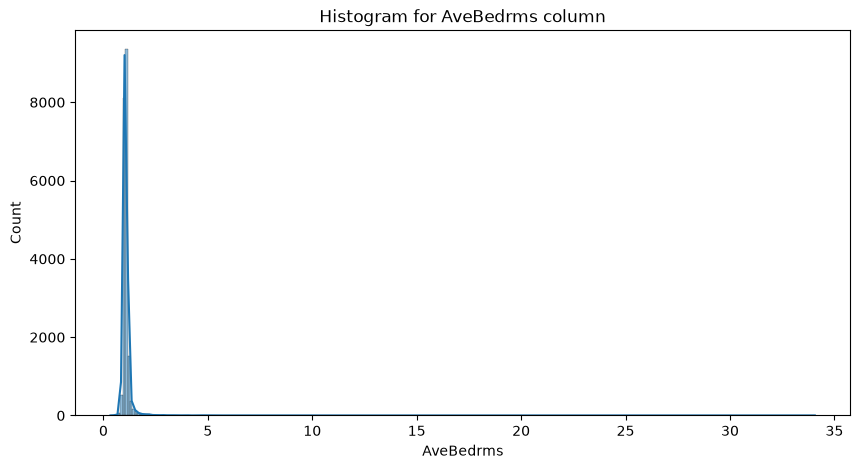

In [22]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='AveBedrms', kde=True)
ax.set_title("Histogram for AveBedrms column")
plt.show()

In [23]:
print(f"Skewness: {data_copy['AveBedrms'].skew()}")

Skewness: 31.316956246782674


***The AveBedrms column is positively skewed. So log transformation has to be performed on this column.***

In [24]:
log_columns.append('AveBedrms')

### **Population column**

#### Checking for outliers

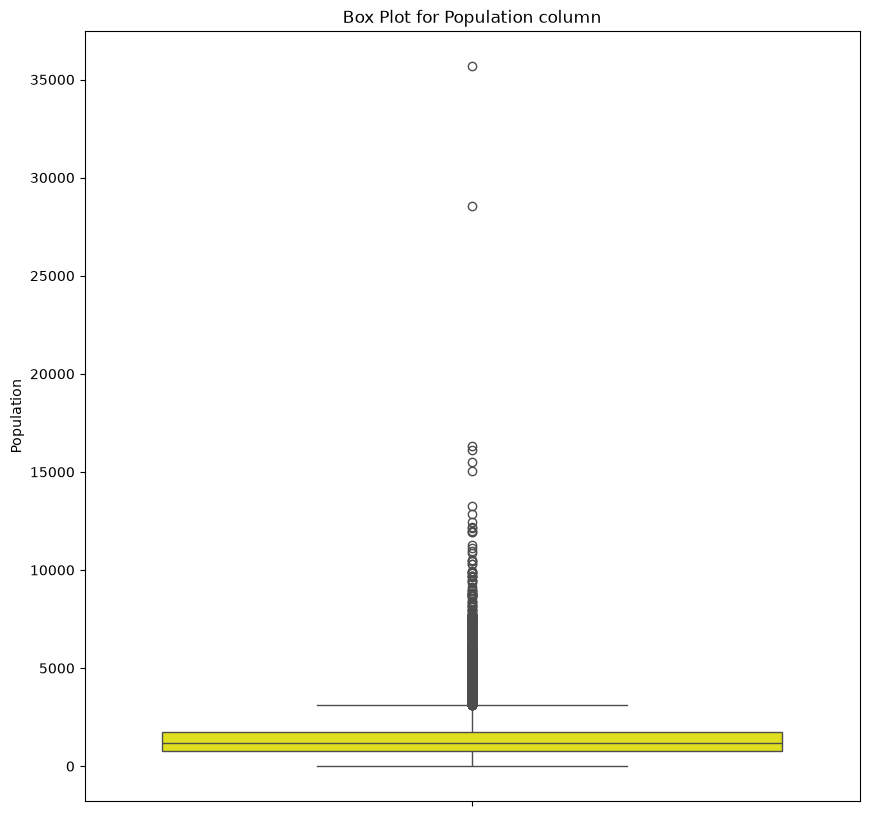

In [25]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='Population', color='yellow')
ax.set_title("Box Plot for Population column")
plt.show()

***Outliers have been identified in the Population column.***

#### Checking for skewness

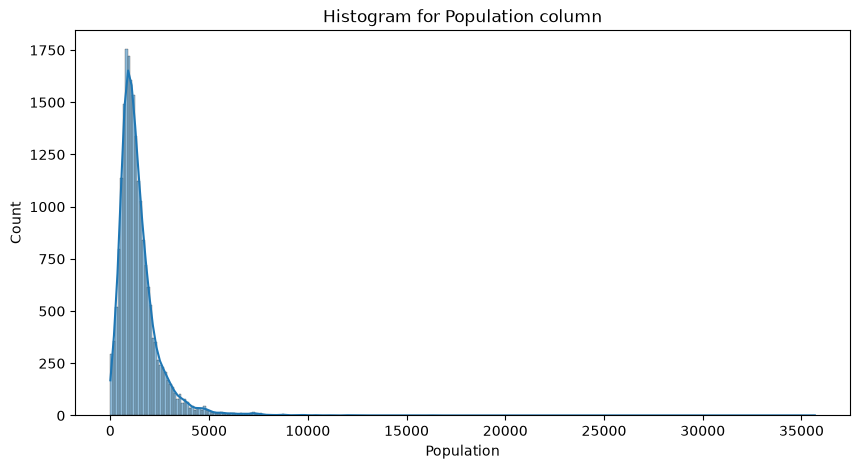

In [26]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='Population', kde=True)
ax.set_title("Histogram for Population column")
plt.show()

In [27]:
print(f"Skewness: {data_copy['Population'].skew()}")

Skewness: 4.935858226727124


***The Population column is positively skewed. So log transformation has to be performed on this column.***

In [28]:
log_columns.append('Population')

### **AveOccup column**

#### Checking for outliers

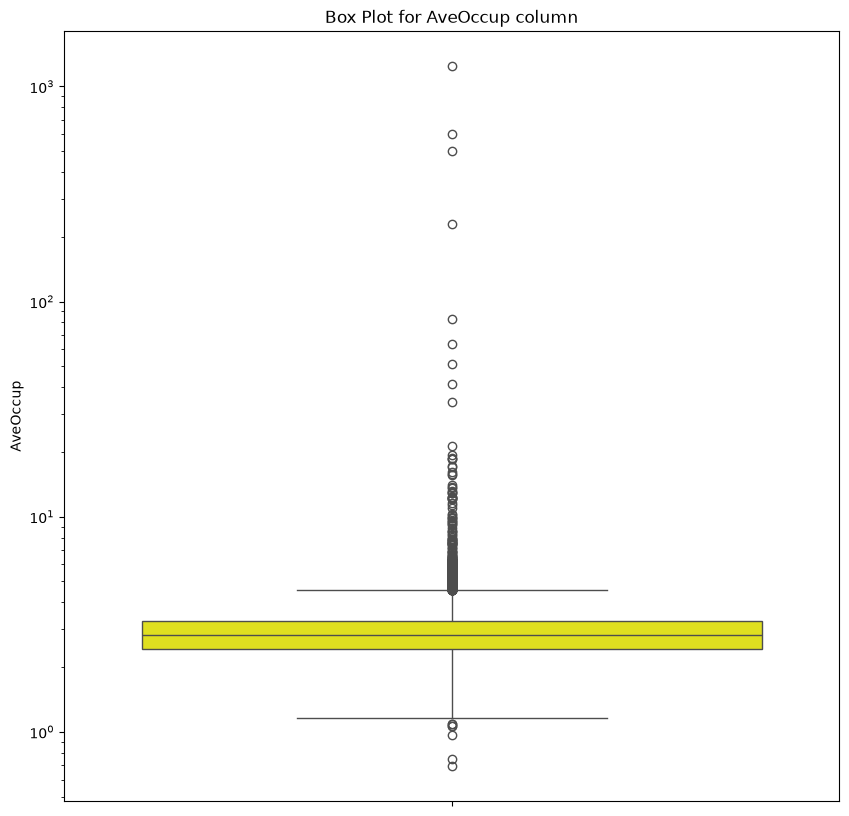

In [29]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='AveOccup', color='yellow')
ax.set_title("Box Plot for AveOccup column")
ax.set_yscale('log')
plt.show()

***A logarithmic scale is used to make the box plot visible.***

***Outliers have been identified in the AveOccup column.***

#### Checking for skewness

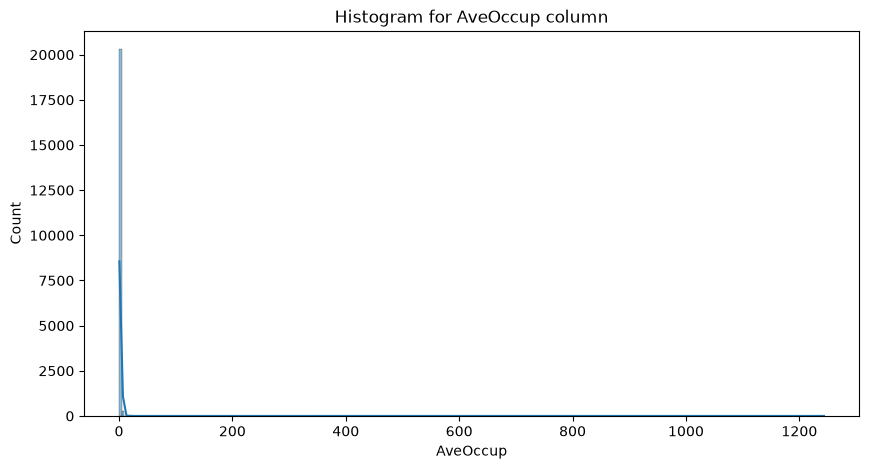

In [30]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='AveOccup', kde=True)
ax.set_title("Histogram for AveOccup column")
plt.show()

In [31]:
print(f"Skewness: {data_copy['AveOccup'].skew()}")

Skewness: 97.63956096369486


***The AveOccup column is positively skewed. So log transformation has to performed on this column.***

In [32]:
log_columns.append('AveOccup')

***Since Latitude and Longitude are geometrical values, they are not checked for outliers or skewness.***

#### **MedHouseVal column**

#### Checking for outliers

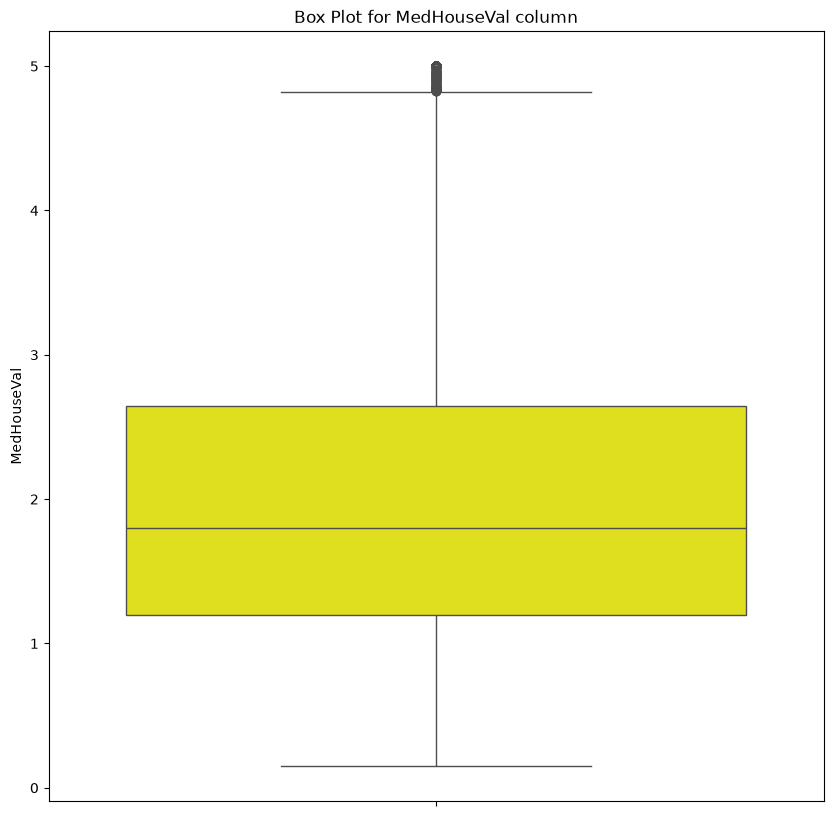

In [33]:
# Plotting a box plot
fig, ax=plt.subplots(figsize=(10,10))
sns.boxplot(data=data_copy, y='MedHouseVal', color='yellow')
ax.set_title("Box Plot for MedHouseVal column")
plt.show()

***Outliers have been identified in the MedHouseVal column.***

#### Checking for skewness

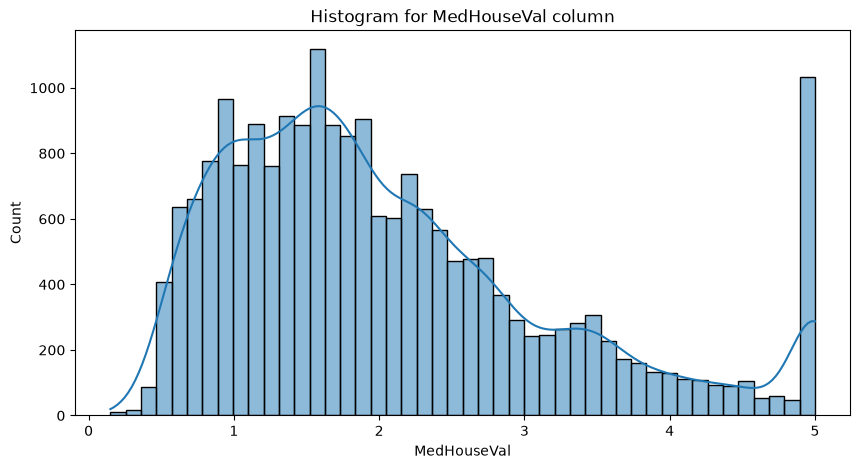

In [34]:
# Plotting histogram
fig, ax=plt.subplots(figsize=(10,5))
sns.histplot(data=data_copy, x='MedHouseVal', kde=True)
ax.set_title("Histogram for MedHouseVal column")
plt.show()

In [35]:
print(f"Skewness: {data_copy['MedHouseVal'].skew()}")

Skewness: 0.9777632739098335


***The data is moderately and positively skewed. So squareroot transformation has to be performed on this column.***

## Selecting the target

In [36]:
y=data_copy['MedHouseVal']

## Selecting the features

In [37]:
X=data_copy.drop('MedHouseVal',axis=1)

## Train - Test split

In [38]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

## Transformation

In [39]:
X_train_log=X_train.copy()
X_test_log=X_test.copy()
X_train_log[log_columns]=np.log1p(X_train[log_columns])
X_test_log[log_columns]=np.log1p(X_test[log_columns])
y_train_squareroot=np.sqrt(y_train)
y_test_squareroot=np.sqrt(y_test)

***Log transformations and squareroot transformation have been performed to reduce the skewness of the columns.***

## Scaling

In [40]:
standard_scaler=StandardScaler()
X_train_scaled=standard_scaler.fit_transform(X_train_log)
X_test_scaled=standard_scaler.transform(X_test_log)

***Standard scaling is done on the features to scale them all to a common range.***

## Training the models

### **Linear Regression**

***Linear Regression is a regression model used to predict a continous numerical value based on independent features. Linear regression assumes a linear relationship between the dependent variable and independent variables and aims to find the best fit line.***

#### Training

In [41]:
linear_regression_model=LinearRegression()
linear_regression_model.fit(X_train_scaled, y_train_squareroot)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.28, 0.04,-0.07,...,-0.08,-0.33,-0.31]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.386
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[185.45,171.03,146.12,...,100.65, 53.34, 28.25]"


#### Predicting

In [42]:
y_pred_linear_regression_square_root=linear_regression_model.predict(X_test_scaled)
y_pred_linear_regression=np.square(y_pred_linear_regression_square_root)

#### Mean Absolute Error(MAE)

In [43]:
linear_regression_mean_absolute_error=mean_absolute_error(y_true=y_test, y_pred=y_pred_linear_regression)
print(f"Mean Absolute Error(MAE): {linear_regression_mean_absolute_error}")

Mean Absolute Error(MAE): 0.4807137429582942


#### Mean Squared Error(MSE)

In [44]:
linear_regression_mean_squared_error=mean_squared_error(y_true=y_test, y_pred=y_pred_linear_regression)
print(f"Mean Squared Error(MSE): {linear_regression_mean_squared_error}")

Mean Squared Error(MSE): 0.4547795176019518


#### R2 Score

In [45]:
linear_regression_r2_score=r2_score(y_true=y_test,y_pred=y_pred_linear_regression)
print(f"R2 Score: {linear_regression_r2_score}")

R2 Score: 0.6529484114093522


### **Decision Tree Regressor**

***Decision Tree Regressor is a supervised learning algorithm used for regression. It creates a tree like structure where the internal nodes represents the features and branches represent the rules. The tree starts from the root node and ends in leaf nodes indicating the results.***

#### Training

In [46]:
decision_tree_regressor=DecisionTreeRegressor()
decision_tree_regressor.fit(X_train_scaled, y_train_squareroot)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree wi

#### Plotting the tree

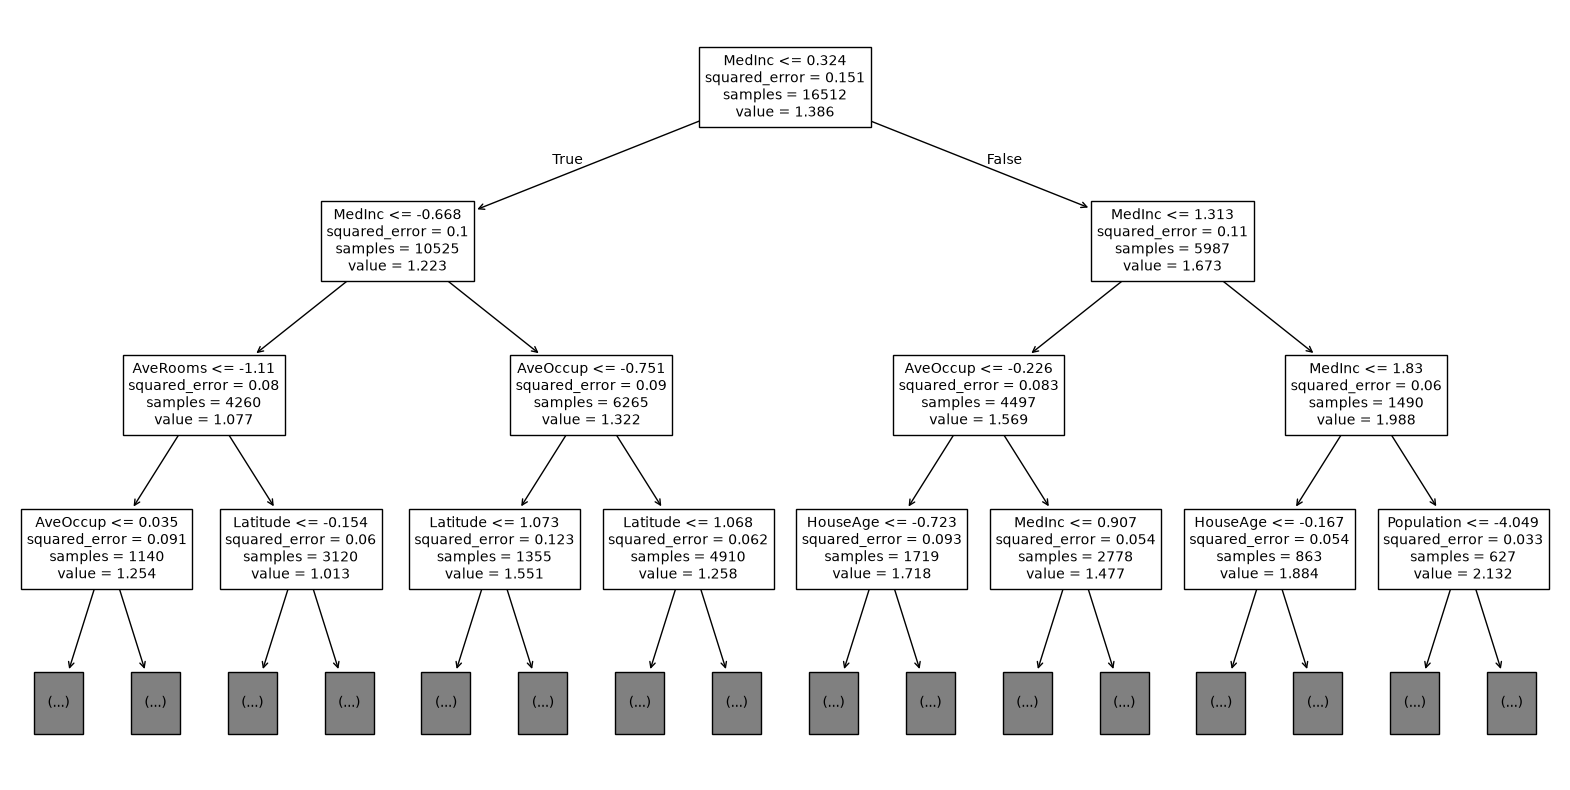

In [47]:
fig, ax=plt.subplots(figsize=(20,10))
plot_tree(
    decision_tree=decision_tree_regressor,
    feature_names=X.columns,
    max_depth=3,
    fontsize=10,
    ax=ax
)
plt.show()

#### Predicting

In [48]:
y_pred_decision_tree_regressor_square_root=decision_tree_regressor.predict(X_test_scaled)
y_pred_decision_tree_regressor=np.square(y_pred_decision_tree_regressor_square_root)

#### Mean Absolute Error(MAE)

In [49]:
decision_tree_regressor_mean_absolute_error=mean_absolute_error(y_true=y_test, y_pred=y_pred_decision_tree_regressor)
print(f"Mean Absolute Error(MAE): {decision_tree_regressor_mean_absolute_error}")

Mean Absolute Error(MAE): 0.434728578003876


#### Mean Squared Error(MSE)

In [50]:
decision_tree_regressor_mean_squared_error=mean_squared_error(y_true=y_test,y_pred=y_pred_decision_tree_regressor)
print(f"Mean Squared Error(MSE): {decision_tree_regressor_mean_squared_error}")

Mean Squared Error(MSE): 0.48339199666078003


#### R2 Score

In [51]:
decision_tree_regressor_r2_score=r2_score(y_true=y_test, y_pred=y_pred_decision_tree_regressor)
print(f"R2 Score: {decision_tree_regressor_r2_score}")

R2 Score: 0.6311136410941811


### **Random Forest Regressor**

***Random Forest Regressor is an ensemble learning technique that takes multiple samples from the dataset with replacement and trains a seperate decision tree model for each sample and takes the average of the predictions made by all the trees as the final result.***

#### Training

In [52]:
random_forest_regressor=RandomForestRegressor(random_state=42)
random_forest_regressor.fit(X_train_scaled, y_train_squareroot)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

#### Predicting

In [53]:
y_pred_random_forest_regressor_square_root=random_forest_regressor.predict(X_test_scaled)
y_pred_random_forest_regressor=np.square(y_pred_random_forest_regressor_square_root)

#### Mean Absolute Error(MAE)

In [54]:
random_forest_regressor_mean_absolute_error=mean_absolute_error(y_true=y_test, y_pred=y_pred_random_forest_regressor)
print(f"Mean Absolute Error(MAE): {random_forest_regressor_mean_absolute_error}")

Mean Absolute Error(MAE): 0.32203765384104327


#### Mean Squared Error(MSE)

In [55]:
random_forest_regressor_mean_squared_error=mean_squared_error(y_true=y_test,y_pred=y_pred_random_forest_regressor)
print(f"Mean Squared Error(MSE): {random_forest_regressor_mean_squared_error}")

Mean Squared Error(MSE): 0.25818190918701744


#### R2 Score

In [56]:
random_forest_regressor_r2_score=r2_score(y_true=y_test, y_pred=y_pred_random_forest_regressor)
print(f"R2 Score: {random_forest_regressor_r2_score}")

R2 Score: 0.8029760834410626


### **Gradient Boosting Regressor**

***Gradient Boosting Regressor is an ensemble technique that builds new decision trees sequentally so that each new tree corrects the errors of the previous one.***

#### Training

In [57]:
gradient_boosting_regressor=GradientBoostingRegressor(random_state=42)
gradient_boosting_regressor.fit(X_train_scaled, y_train_squareroot)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

#### Predicting

In [58]:
y_pred_gradient_boosting_regressor_square_root=gradient_boosting_regressor.predict(X_test_scaled)
y_pred_gradient_boosting_regressor=np.square(y_pred_gradient_boosting_regressor_square_root)

#### Mean Absolute Error(MAE)

In [59]:
gradient_boosting_regressor_mean_absolute_error=mean_absolute_error(y_true=y_test,y_pred=y_pred_gradient_boosting_regressor)
print(f"Mean Absolute Error(MAE): {gradient_boosting_regressor_mean_absolute_error}")

Mean Absolute Error(MAE): 0.36646224223426604


#### Mean Squared Error(MSE)

In [60]:
gradient_boosting_regressor_mean_squared_error=mean_squared_error(y_true=y_test, y_pred=y_pred_gradient_boosting_regressor)
print(f"Mean Squared Error(MSE): {gradient_boosting_regressor_mean_squared_error}")

Mean Squared Error(MSE): 0.295665414594225


#### R2 Score

In [61]:
gradient_boosting_regressor_r2_score=r2_score(y_true=y_test, y_pred=y_pred_gradient_boosting_regressor)
print(f"R2 Score: {gradient_boosting_regressor_r2_score}")

R2 Score: 0.7743716507565997


### **Support Vector Regressor**

***Support Vector Regressor is a supervised learning technique used for regression. It constructs a hyperplane in a high dimensional space to fit the data points.***

#### Training

In [62]:
support_vector_regressor=SVR()
support_vector_regressor.fit(X_train_scaled, y_train_squareroot)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


#### Predicting

In [63]:
y_pred_support_vector_regressor_square_root=support_vector_regressor.predict(X_test_scaled)
y_pred_support_vector_regressor=np.square(y_pred_support_vector_regressor_square_root)

#### Mean Absolute Error(MAE)

In [64]:
support_vector_regressor_mean_absolute_error=mean_absolute_error(y_true=y_test, y_pred=y_pred_support_vector_regressor)
print(f"Mean Absolute Error(MAE): {support_vector_regressor_mean_absolute_error}")

Mean Absolute Error(MAE): 0.36491939396801293


#### Mean Squared Error(MSE)

In [65]:
support_vector_regressor_mean_squared_error=mean_squared_error(y_true=y_test, y_pred=y_pred_support_vector_regressor)
print(f"Mean Squared Error(MSE): {support_vector_regressor_mean_squared_error}")

Mean Squared Error(MSE): 0.29444750946687415


#### R2 Score

In [66]:
support_vector_regressor_r2_score=r2_score(y_true=y_test, y_pred=y_pred_support_vector_regressor)
print(f"R2 Score: {support_vector_regressor_r2_score}")

R2 Score: 0.7753010591684574


## Comparing Models

### Creating a dataframe for comparison

In [67]:
comparison=pd.DataFrame({
    'model':['Linear Regression','Decision Tree Regressor','Random Forest Regressor','Gradient Boosting Regressor','Support Vector Regressor'],
    'mean_absolute_error':[linear_regression_mean_absolute_error, decision_tree_regressor_mean_absolute_error, random_forest_regressor_mean_absolute_error, gradient_boosting_regressor_mean_absolute_error, support_vector_regressor_mean_absolute_error],
    'mean_squared_error':[linear_regression_mean_squared_error, decision_tree_regressor_mean_squared_error, random_forest_regressor_mean_squared_error, gradient_boosting_regressor_mean_squared_error, support_vector_regressor_mean_squared_error],
    'r2_score':[linear_regression_r2_score, decision_tree_regressor_r2_score, random_forest_regressor_r2_score, gradient_boosting_regressor_r2_score, support_vector_regressor_r2_score]
})

In [68]:
comparison

,model,mean_absolute_error,mean_squared_error,r2_score
0,Linear Regression,0.480714,0.454780,0.652948
1,Decision Tree Regressor,0.434729,0.483392,0.631114
2,Random Forest Regressor,0.322038,0.258182,0.802976
3,Gradient Boosting Regressor,0.366462,0.295665,0.774372
4,Support Vector Regressor,0.364919,0.294448,0.775301


### Plotting graph for comparing models

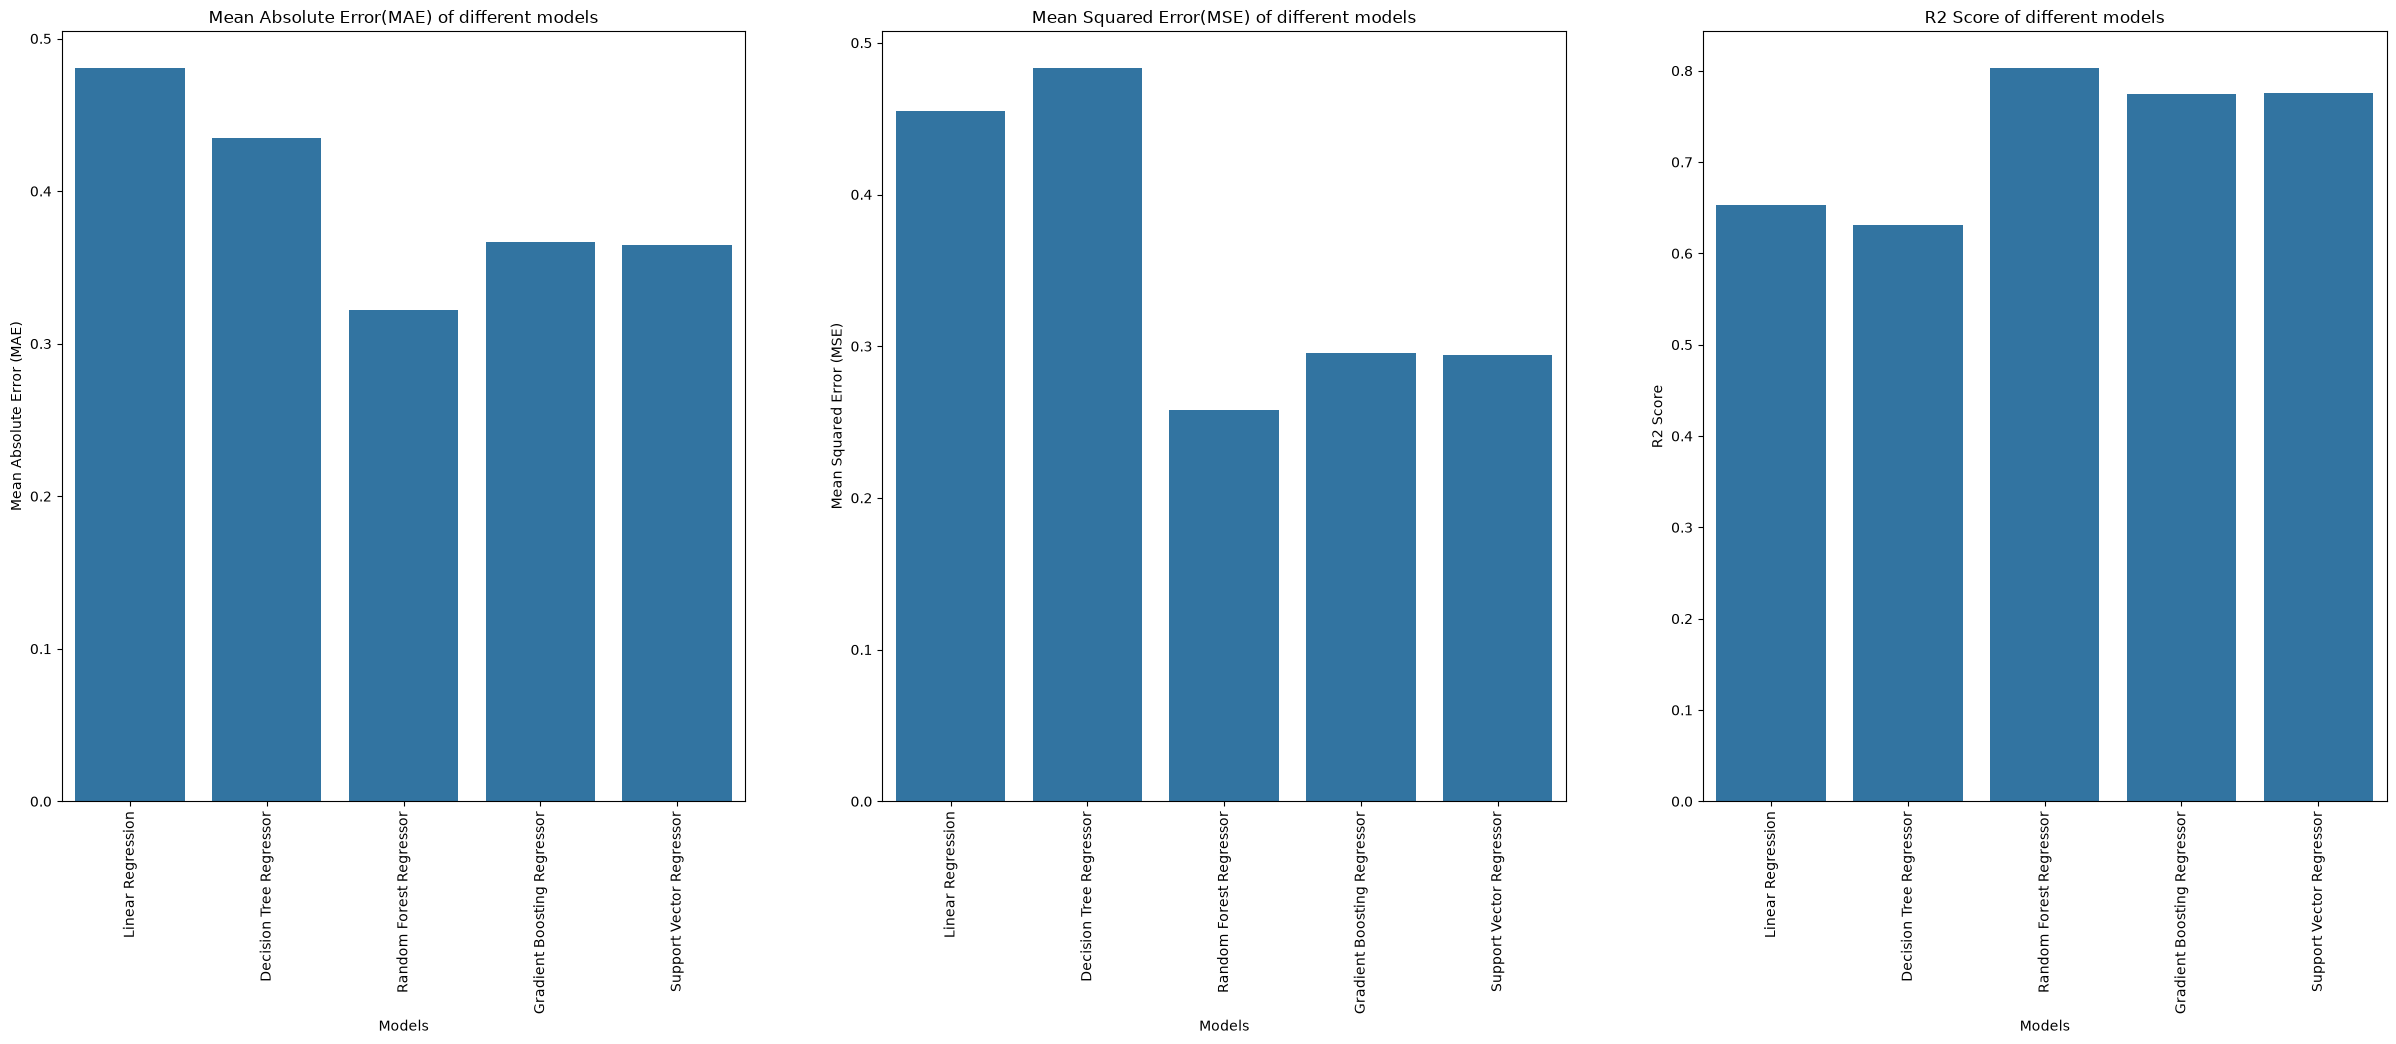

In [69]:
fig, ax=plt.subplots(1,3,figsize=(30,10))
sns.barplot(data=comparison, x='model', y='mean_absolute_error', ax=ax[0])
ax[0].set_title("Mean Absolute Error(MAE) of different models")
ax[0].set_xlabel("Models")
ax[0].set_ylabel("Mean Absolute Error (MAE)")
ax[0].tick_params(axis='x', rotation=90)
sns.barplot(data=comparison, x='model', y='mean_squared_error', ax=ax[1])
ax[1].set_title("Mean Squared Error(MSE) of different models")
ax[1].set_xlabel("Models")
ax[1].set_ylabel("Mean Squared Error (MSE)")
ax[1].tick_params(axis='x', rotation=90)
sns.barplot(data=comparison, x='model', y='r2_score', ax=ax[2])
ax[2].set_title("R2 Score of different models")
ax[2].set_xlabel("Models")
ax[2].set_ylabel("R2 Score")
ax[2].tick_params(axis='x', rotation=90)
plt.show()

## Conclusion

1. Based on mean absolute error, mean squared error and r2 score, Random Forest Regressor is the best performing algorithm because it creates multiple subsets from the dataset with replacement and trains a seperate decision tree on each subset. The final result is calculated by taking the average of predictions made by all the decision trees. It reduces overfitting and the model is more robust to noise.
2. Based on mean squared error and r2 score, Decision Tree Regressor is the worst performing algorithm which may be due to overfitting.
3. Based on mean absolute error, Linear Regression is the worst performing algorithm because it assumes a linear relationship between the dependent and independent variables but the relationship may not actually be linear.